# Comparing Two Methods on the Same Bootstrap Draws

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

`BootstrapODPSample` gives a distribution of IBNR for each reserving
choice. Two histograms side by side, as in
{doc}`BootstrapODPSample Variability <plot_bootstrap_comparison>`, show how
wide each distribution is. They do not show how far apart two choices
are on the same data. That needs the difference between the two methods
on each simulated triangle.

Fitting both methods to the same resampled triangles gives that
difference directly {cite}`shapland2016`. Both methods see the same
simulated claims, so most of the sampling noise cancels out of the
difference. This example compares `TailCurve` with `TailBondy` on
`genins`, once on shared draws and once on draws from a second seed.

In [2]:
genins = cl.load_sample("genins")


def total_ibnr(triangles, tail):
    developed = tail.fit_transform(cl.Development().fit_transform(triangles))
    return cl.Chainladder().fit(developed).ibnr_.sum("origin").values.flatten()


sims = cl.BootstrapODPSample(n_sims=1000, random_state=42).fit_transform(genins)
other = cl.BootstrapODPSample(n_sims=1000, random_state=7).fit_transform(genins)

curve = total_ibnr(sims, cl.TailCurve())
bondy = total_ibnr(sims, cl.TailBondy())
bondy_other = total_ibnr(other, cl.TailBondy())

differences = pd.DataFrame({
    "Same draws": bondy - curve,
    "Independent draws": bondy_other - curve,
})
differences.describe(percentiles=[0.05, 0.5, 0.95]).T.round(0)

,count,mean,std,min,5%,50%,95%,max
Same draws,1000.0,-696715.0,1540822.0,-5697463.0,-3309382.0,-686915.0,1790523.0,4237244.0
Independent draws,1000.0,-702384.0,4728455.0,-14099955.0,-8044041.0,-955422.0,7262379.0,16383097.0


In [3]:
def point_ibnr(tail):
    developed = tail.fit_transform(cl.Development().fit_transform(genins))
    return cl.Chainladder().fit(developed).ibnr_.sum()


point = pd.Series({
    "TailCurve": point_ibnr(cl.TailCurve()),
    "TailBondy": point_ibnr(cl.TailBondy()),
})
point["Difference"] = point["TailBondy"] - point["TailCurve"]
point.round(0)

TailCurve     20245461.0
TailBondy     19620956.0
Difference     -624504.0
dtype: float64

Both rows estimate the same mean difference, TailBondy minus TailCurve.
The standard deviation of the shared-draw difference is
1,540,822 against 4,728,455 for independent draws, about
a third as wide. On the original triangle TailCurve gives total
IBNR of 20,245,461 and TailBondy gives 19,620,956, a difference of
-624,504.

The variance of a difference explains the gap:

$$
\operatorname{Var}(B - C) = \operatorname{Var}(B) + \operatorname{Var}(C) - 2\operatorname{Cov}(B, C)
$$

With independent draws the covariance is zero. With shared draws the two
totals move together, and the covariance cancels most of the variance.
When the two methods have about the same standard deviation $\sigma$
and correlation $\rho$, the shared-draw variance is
$2\sigma^2(1 - \rho)$ against $2\sigma^2$, so the ratio of standard
deviations is close to $\sqrt{1 - \rho}$.

In [4]:
rho = np.corrcoef(curve, bondy)[0, 1]
sd_curve = curve.std(ddof=1)
sd_bondy = bondy.std(ddof=1)
sd_identity = np.sqrt(sd_bondy**2 + sd_curve**2 - 2 * rho * sd_bondy * sd_curve)
sd_same = differences["Same draws"].std()
sd_independent = differences["Independent draws"].std()
pd.Series({
    "Correlation of TailCurve and TailBondy": rho,
    "sd of the difference from the identity": sd_identity,
    "sd of the difference on shared draws": sd_same,
    "sqrt(1 - correlation)": np.sqrt(1 - rho),
    "Ratio of shared to independent sd": sd_same / sd_independent,
}).round(3)

Correlation of TailCurve and TailBondy          0.885
sd of the difference from the identity    1540821.818
sd of the difference on shared draws      1540821.818
sqrt(1 - correlation)                           0.338
Ratio of shared to independent sd               0.326
dtype: float64

The correlation is 0.885, so $\sqrt{1 - \rho}$ is 0.338 and the
observed ratio is 0.326. The identity reproduces the shared-draw
standard deviation exactly, because it uses the sample covariance of the
same draws.

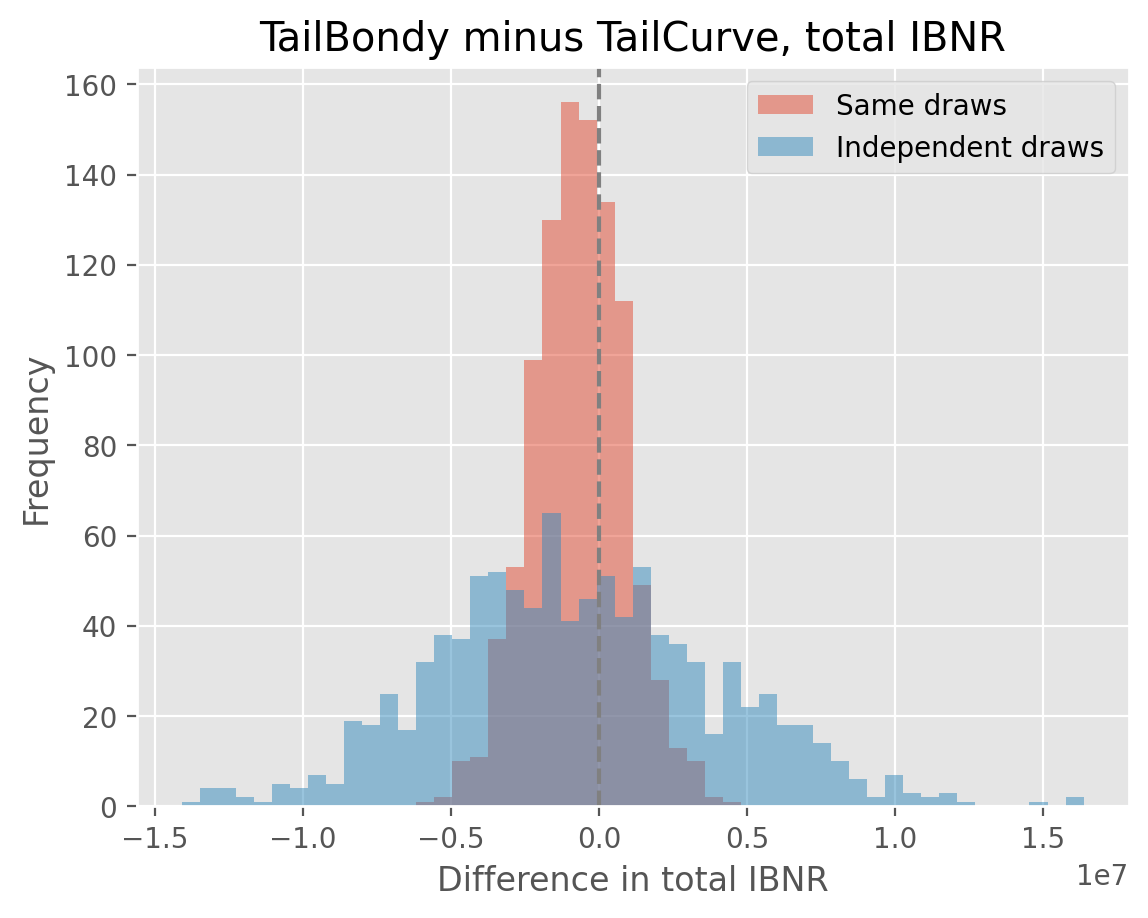

In [5]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

ax = differences.plot(
    kind="hist",
    bins=50,
    alpha=0.5,
    grid=True,
    title="TailBondy minus TailCurve, total IBNR",
    xlabel="Difference in total IBNR",
)
ax.axvline(0, color="grey", linestyle="--");

More draws do not close this gap. Each standard deviation describes the
spread of one difference across simulated triangles, and it settles at
its own value as the number of draws grows. What more draws shrink is
the standard error of the mean difference, which falls like
$1 / \sqrt{n}$.

In [6]:
rows = []
for n in (200, 1000, 2000):
    sims_n = cl.BootstrapODPSample(n_sims=n, random_state=42).fit_transform(genins)
    other_n = cl.BootstrapODPSample(n_sims=n, random_state=7).fit_transform(genins)
    curve_n = total_ibnr(sims_n, cl.TailCurve())
    same = total_ibnr(sims_n, cl.TailBondy()) - curve_n
    independent = total_ibnr(other_n, cl.TailBondy()) - curve_n
    rows.append({
        "Draws": n,
        "sd, same draws": same.std(ddof=1),
        "sd, independent draws": independent.std(ddof=1),
        "Ratio": same.std(ddof=1) / independent.std(ddof=1),
        "Mean, same draws": same.mean(),
        "Standard error of the mean": same.std(ddof=1) / np.sqrt(n),
    })
by_draws = pd.DataFrame(rows).set_index("Draws")
by_draws["Mean over standard error"] = (
    by_draws["Mean, same draws"] / by_draws["Standard error of the mean"]
)
by_draws.round(0).assign(**{
    "Ratio": by_draws["Ratio"].round(3),
    "Mean over standard error": by_draws["Mean over standard error"].round(1),
})

,"sd, same draws","sd, independent draws",Ratio,"Mean, same draws",Standard error of the mean,Mean over standard error
Draws,,,,,,
200,1488592.0,4917204.0,0.303,-537354.0,105259.0,-5.1
1000,1540822.0,4728455.0,0.326,-696715.0,48725.0,-14.3
2000,1580905.0,4773806.0,0.331,-688972.0,35350.0,-19.5


The ratio stays between 0.303 and 0.331 from 200 to 2,000 draws.
The standard error of the shared-draw mean falls from 105,259 to
35,350, so the mean difference of -688,972 at 2,000 draws sits
about 19.5 standard errors below zero. With independent draws
the standard error would be about three times as large at every number
of draws, since it scales with the wider standard deviation.

The comparison depends on one seed giving the same draws to both
methods. Fit each method to the output of a single
`BootstrapODPSample.fit_transform` call, as above, rather than
resampling once per method.